# ACA N° 2 – Aprendizaje Automático
## Predicción del rendimiento académico con Redes Neuronales (MLP) – Dataset xAPI-Edu-Data

**Corporación Unificada Nacional de Educación Superior (CUN)** · Especialización en Inteligencia Artificial
Asignatura: Aprendizaje Automático · Docente: Hamilton Rivera Flor

**Proyecto 2: Educación.** El objetivo es predecir el nivel de rendimiento de un estudiante
(**L** = bajo, **M** = medio, **H** = alto) a partir de su comportamiento en la plataforma de aprendizaje
(Kalboard 360), variables demográficas, académicas y de participación de los padres.

**Pregunta orientadora:** ¿Cómo aprovechar una red neuronal (Perceptrón Multicapa profundo) para extraer patrones
en los datos de interacción de los estudiantes, optimizando el rendimiento predictivo y permitiendo su uso
práctico en una interfaz de Streamlit?

| Paso | Contenido |
|---|---|
| 1 | Conexión a los datos (Google Drive), comprensión del problema y EDA |
| 2 | Preparación y pipeline: limpieza, codificación, escalado, partición y aumento de datos |
| 3 | Modelado con red neuronal MLP en PyTorch |
| 4 | Evaluación: Loss, Accuracy, F1-Score, matriz de confusión y curvas |
| 5 | Despliegue en Streamlit (`app.py`) |

> Referencia del dataset: Aljarah, I. (2016). *xAPI-Edu-Data (Student Academic Performance)* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/aljarah/xAPI-Edu-Data

In [1]:
# Librerías
import json, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, log_loss)

import utils  # módulo propio con la conexión a datos, la limpieza y la red neuronal

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

# Reproducibilidad
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
print("PyTorch", torch.__version__)

PyTorch 2.15.0+cu132


---
# PASO 1 · Exploración y gestión de datos

### 1.1 Conexión a la base de datos
El dataset se encuentra en Google Drive:
`https://drive.google.com/file/d/1cIeVbKI3NpUvt3GHW7yuZibyADUCq3uw/view`

La función `utils.cargar_datos()` convierte el enlace en una URL de descarga directa
(`https://drive.google.com/uc?export=download&id=<ID>`) y lee el CSV con `pandas`. Si no hay conexión
o el archivo no está compartido públicamente, usa la copia local `data/xAPI-Edu-Data.csv`, de modo que el notebook
siempre es reproducible. Se mantiene el formato CSV (no se migra a SQL).

In [2]:
print("URL de descarga directa:", utils.DRIVE_URL)
df_raw, ORIGEN = utils.cargar_datos()
df_raw.head()

URL de descarga directa: https://drive.google.com/uc?export=download&id=1cIeVbKI3NpUvt3GHW7yuZibyADUCq3uw


[aviso] No se pudo leer desde Google Drive (ProxyError: HTTPSConnectionPool(host='drive.google.com', port=443): Max retries exceeded with url: /uc?export=download&id=1cIeVbKI3NpUvt3GHW7yuZibyADUCq3uw (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))).
[aviso] Usando copia local: /home/claude/proyecto/data/xAPI-Edu-Data.csv
Datos cargados desde: Copia local -> 480 filas x 17 columnas


,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7,M


### 1.2 Estructura, tipos, nulos y duplicados

In [3]:
print("Dimensiones:", df_raw.shape)
print("Valores nulos totales:", df_raw.isna().sum().sum())
print("Filas duplicadas exactas:", df_raw.duplicated().sum())
df_raw.info()

Dimensiones: (480, 17)
Valores nulos totales: 0
Filas duplicadas exactas: 2
<class 'pandas.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   gender                    480 non-null    str  
 1   NationalITy               480 non-null    str  
 2   PlaceofBirth              480 non-null    str  
 3   StageID                   480 non-null    str  
 4   GradeID                   480 non-null    str  
 5   SectionID                 480 non-null    str  
 6   Topic                     480 non-null    str  
 7   Semester                  480 non-null    str  
 8   Relation                  480 non-null    str  
 9   raisedhands               480 non-null    int64
 10  VisITedResources          480 non-null    int64
 11  AnnouncementsView         480 non-null    int64
 12  Discussion                480 non-null    int64
 13  ParentAnsweringSurvey     480 

In [4]:
# Diccionario de variables
dicc = pd.DataFrame({
    "variable": df_raw.columns,
    "tipo": df_raw.dtypes.astype(str).values,
    "n_valores_unicos": df_raw.nunique().values,
    "ejemplo": df_raw.iloc[0].values,
})
dicc["descripcion"] = [
    "Género del estudiante (M/F)", "Nacionalidad", "País de nacimiento", "Nivel educativo",
    "Grado escolar", "Sección del aula", "Asignatura", "Semestre (F=primero, S=segundo)",
    "Padre responsable (Father/Mum)", "Veces que levantó la mano en clase", "Recursos visitados",
    "Anuncios vistos", "Participación en foros de discusión", "¿El padre respondió la encuesta?",
    "Satisfacción del padre con la escuela", "Días de ausencia (menos/más de 7)",
    "OBJETIVO: nivel de rendimiento L (0-69), M (70-89), H (90-100)"]
dicc

,variable,tipo,n_valores_unicos,ejemplo,descripcion
0,gender,str,2,M,Género del estudiante (M/F)
1,NationalITy,str,14,KW,Nacionalidad
2,PlaceofBirth,str,14,KuwaIT,País de nacimiento
3,StageID,str,3,lowerlevel,Nivel educativo
4,GradeID,str,10,G-04,Grado escolar
5,SectionID,str,3,A,Sección del aula
6,Topic,str,12,IT,Asignatura
7,Semester,str,2,F,"Semestre (F=primero, S=segundo)"
8,Relation,str,2,Father,Padre responsable (Father/Mum)
9,raisedhands,int64,82,15,Veces que levantó la mano en clase


In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
raisedhands,480.0,46.775000,30.779223,0.0,15.75,50.0,75.0,100.0
VisITedResources,480.0,54.797917,33.080007,0.0,20.00,65.0,84.0,99.0
AnnouncementsView,480.0,37.918750,26.611244,0.0,14.00,33.0,58.0,98.0
Discussion,480.0,43.283333,27.637735,1.0,20.00,39.0,70.0,99.0


### 1.3 Variable objetivo

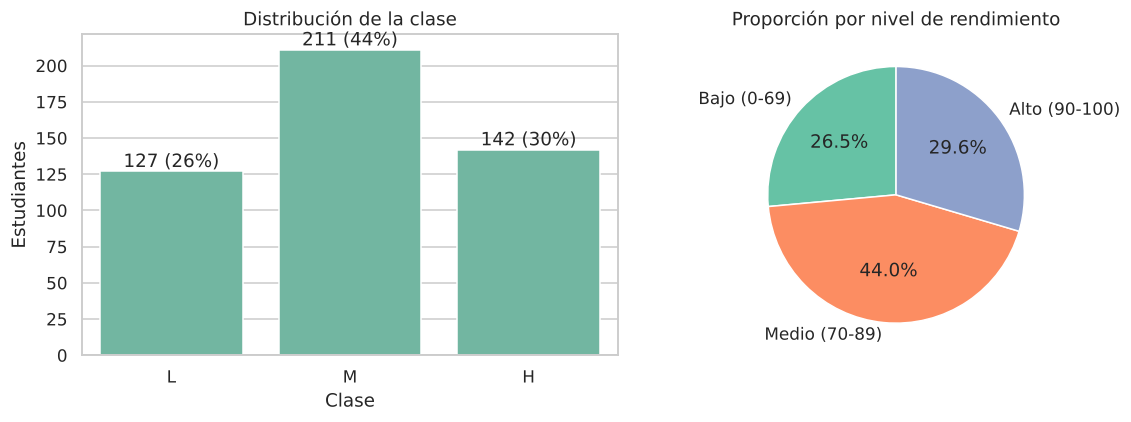

In [6]:
orden = utils.CLASES
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
conteo = df_raw["Class"].value_counts().reindex(orden)
sns.barplot(x=conteo.index, y=conteo.values, ax=ax[0])
ax[0].set_title("Distribución de la clase"); ax[0].set_xlabel("Clase"); ax[0].set_ylabel("Estudiantes")
for i, v in enumerate(conteo.values):
    ax[0].text(i, v + 3, f"{v} ({v/len(df_raw):.0%})", ha="center")
ax[1].pie(conteo.values, labels=[utils.NOMBRE_CLASE[c] for c in orden], autopct="%1.1f%%", startangle=90)
ax[1].set_title("Proporción por nivel de rendimiento")
plt.tight_layout(); plt.show()

### 1.4 Variables numéricas de interacción con la plataforma

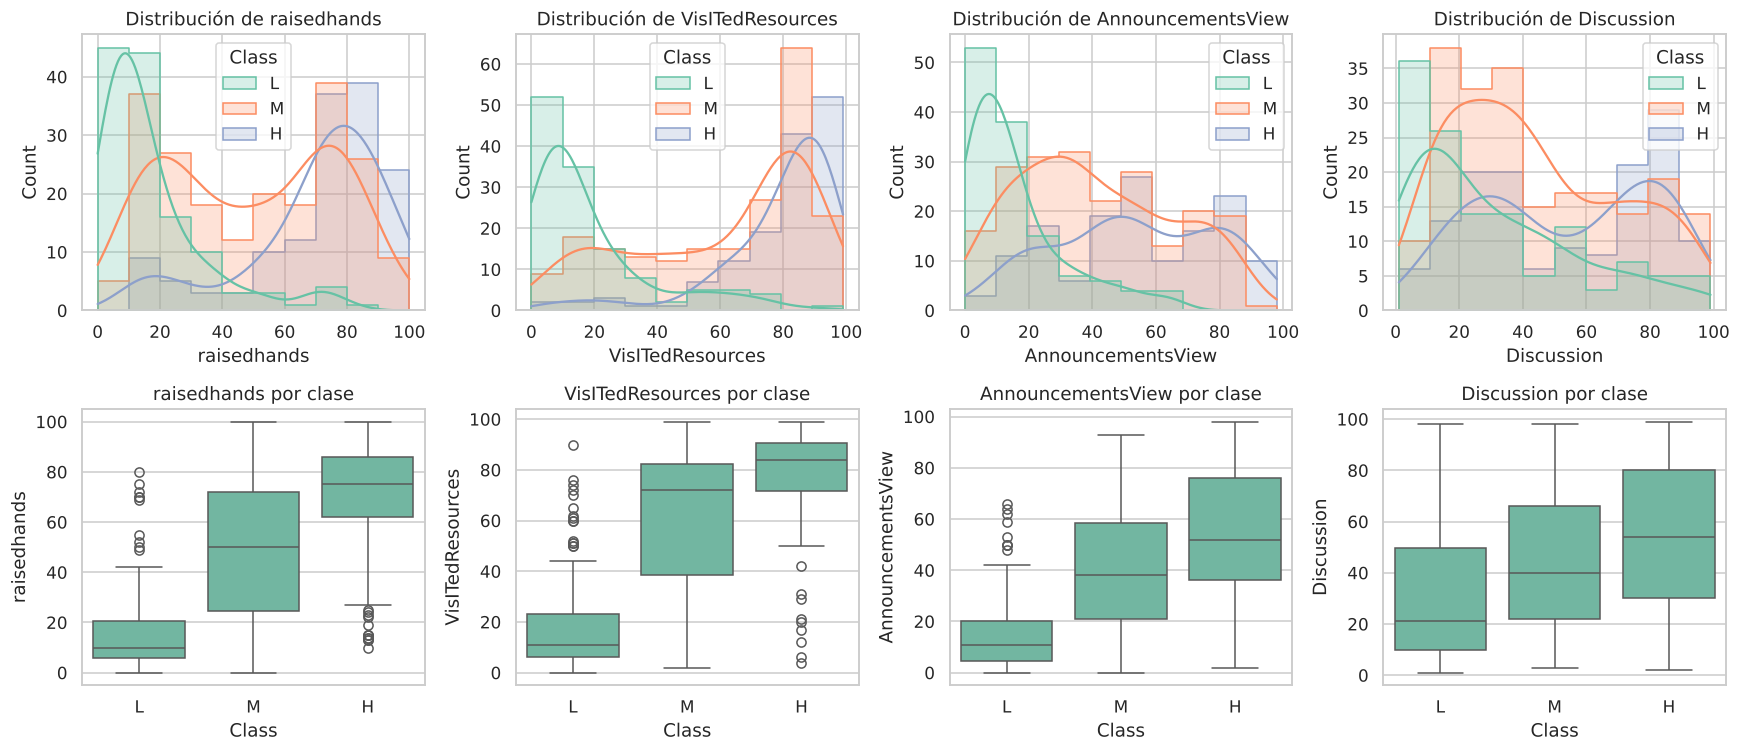

,raisedhands,VisITedResources,AnnouncementsView,Discussion
Class,,,,
L,16.9,18.3,15.6,30.8
M,48.9,60.6,41.0,43.8
H,70.3,78.7,53.4,53.7


In [7]:
num_raw = ["raisedhands", "VisITedResources", "AnnouncementsView", "Discussion"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, c in enumerate(num_raw):
    sns.histplot(data=df_raw, x=c, hue="Class", hue_order=orden, kde=True, element="step", ax=axes[0, i])
    axes[0, i].set_title(f"Distribución de {c}")
    sns.boxplot(data=df_raw, x="Class", y=c, order=orden, ax=axes[1, i])
    axes[1, i].set_title(f"{c} por clase")
plt.tight_layout(); plt.show()

df_raw.groupby("Class")[num_raw].mean().reindex(orden).round(1)

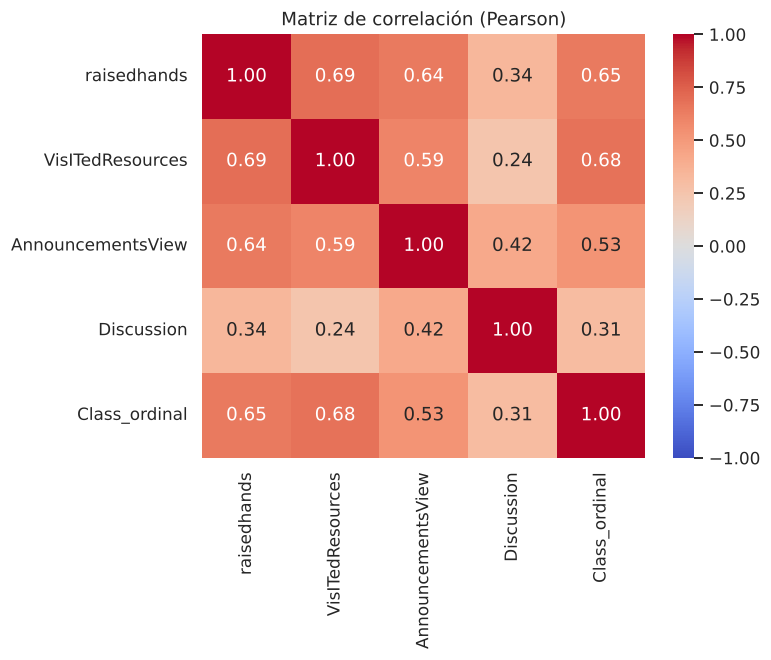

In [8]:
# Correlación entre las variables numéricas y la clase codificada de forma ordinal (L=0, M=1, H=2)
tmp = df_raw[num_raw].copy()
tmp["Class_ordinal"] = df_raw["Class"].map({"L": 0, "M": 1, "H": 2})
plt.figure(figsize=(6.5, 5))
sns.heatmap(tmp.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación (Pearson)"); plt.show()

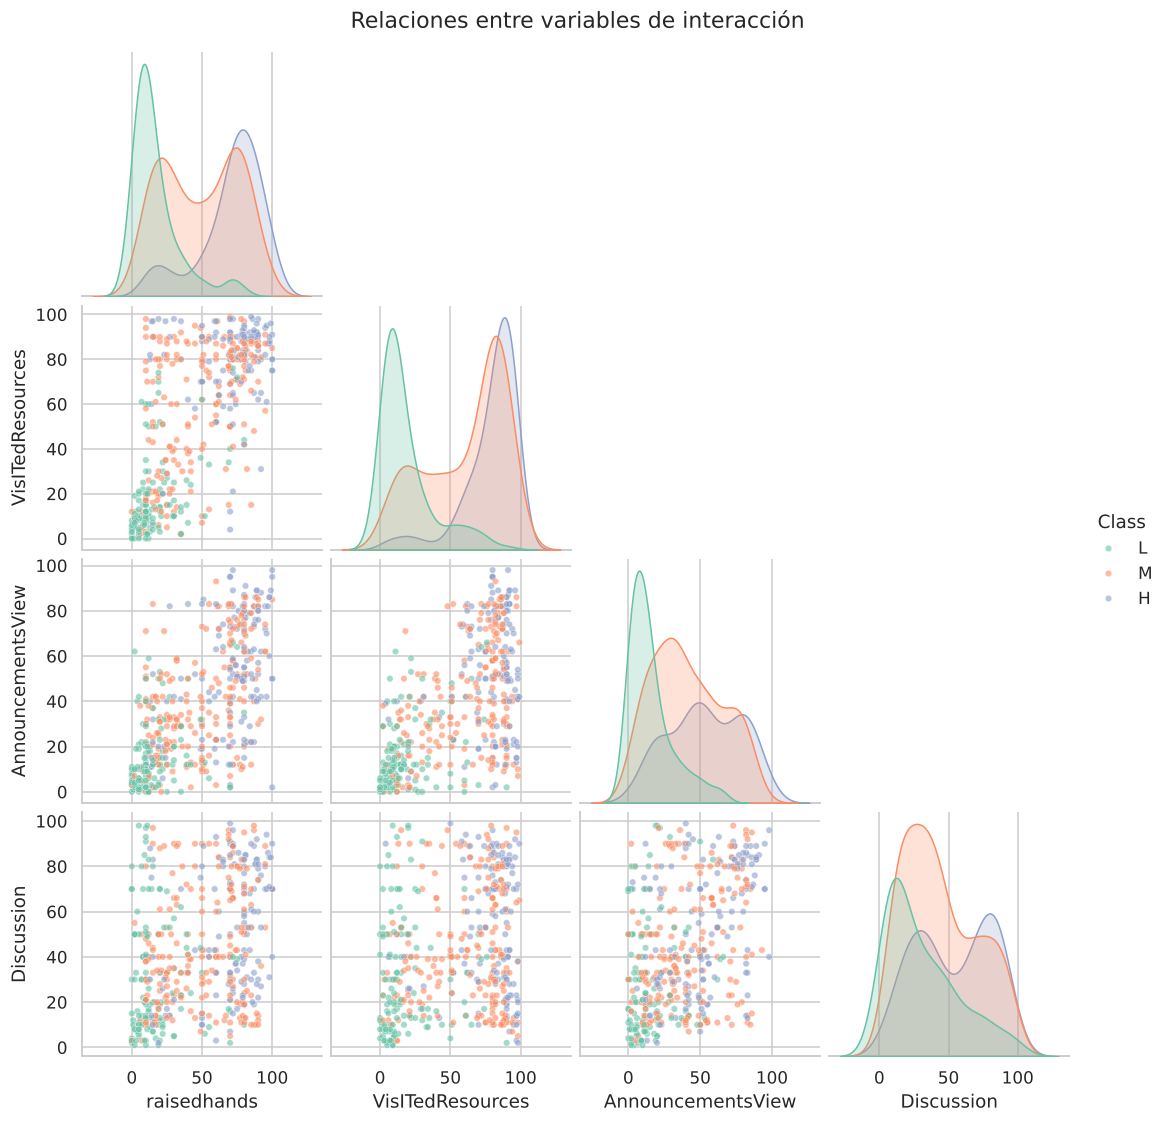

In [9]:
sns.pairplot(df_raw, vars=num_raw, hue="Class", hue_order=orden, corner=True, plot_kws={"alpha": .6, "s": 18})
plt.suptitle("Relaciones entre variables de interacción", y=1.02); plt.show()

### 1.5 Variables categóricas frente a la clase

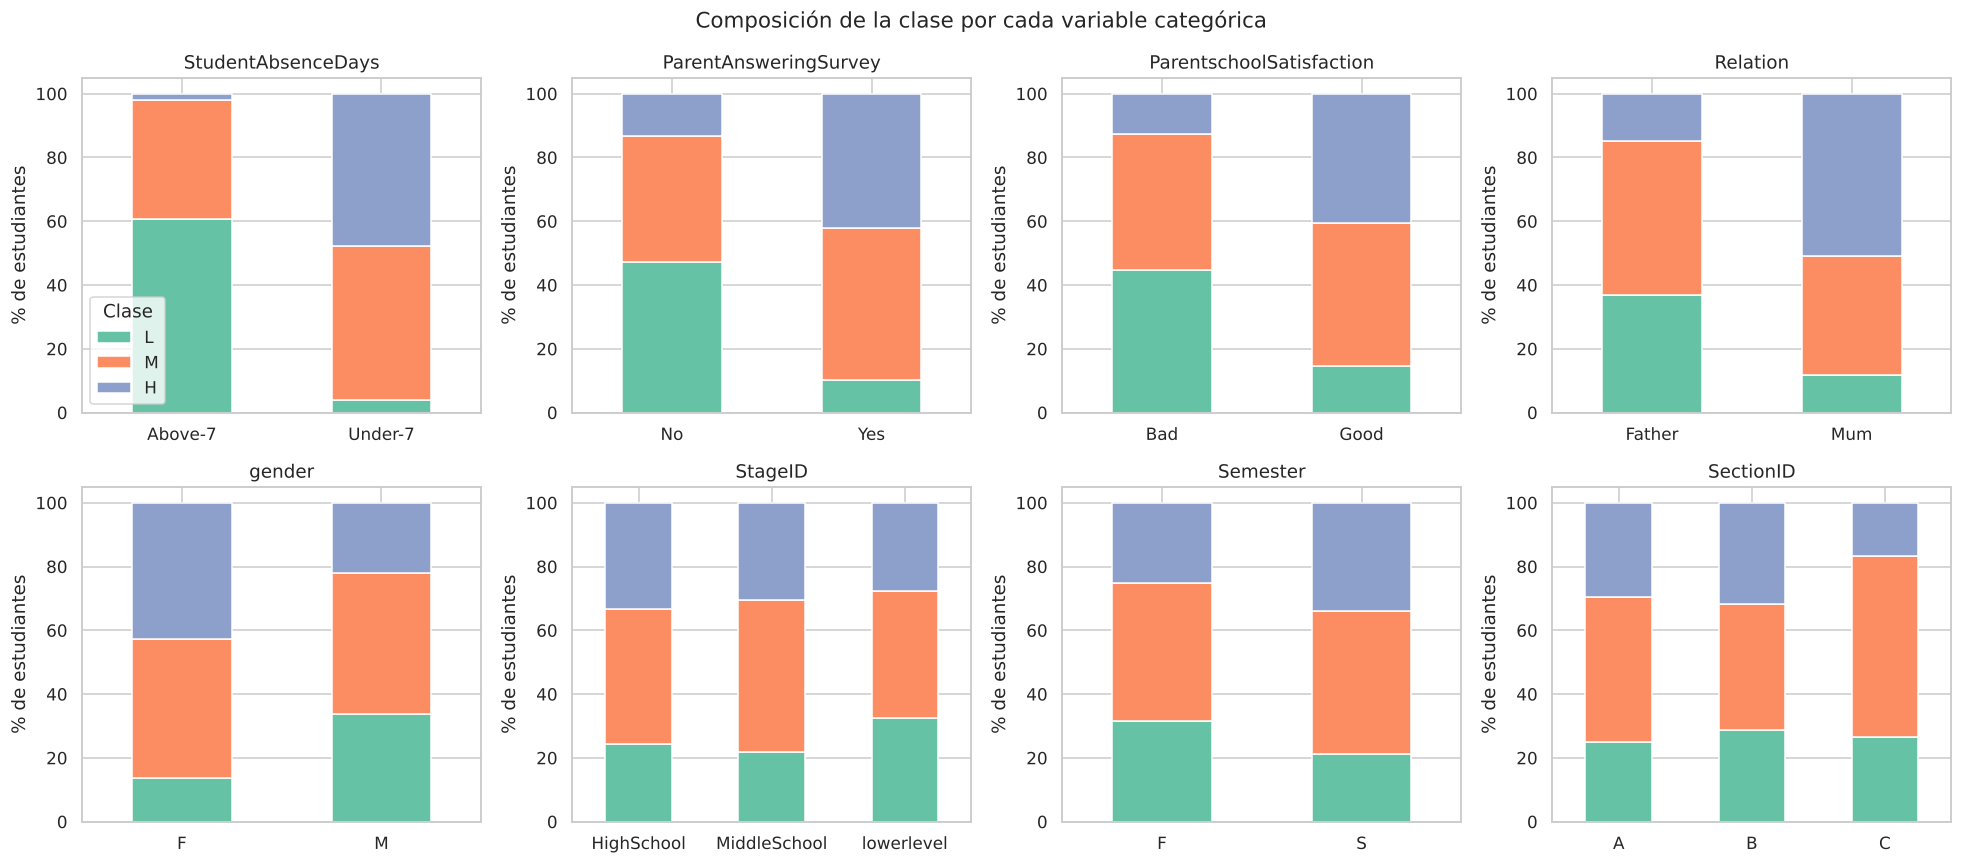

In [10]:
cats = ["StudentAbsenceDays", "ParentAnsweringSurvey", "ParentschoolSatisfaction", "Relation",
        "gender", "StageID", "Semester", "SectionID"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), cats):
    pct = pd.crosstab(df_raw[c], df_raw["Class"], normalize="index")[orden] * 100
    pct.plot(kind="bar", stacked=True, ax=ax, rot=0, legend=False)
    ax.set_title(c); ax.set_ylabel("% de estudiantes"); ax.set_xlabel("")
axes[0, 0].legend(title="Clase", loc="lower left")
plt.suptitle("Composición de la clase por cada variable categórica", fontsize=14)
plt.tight_layout(); plt.show()

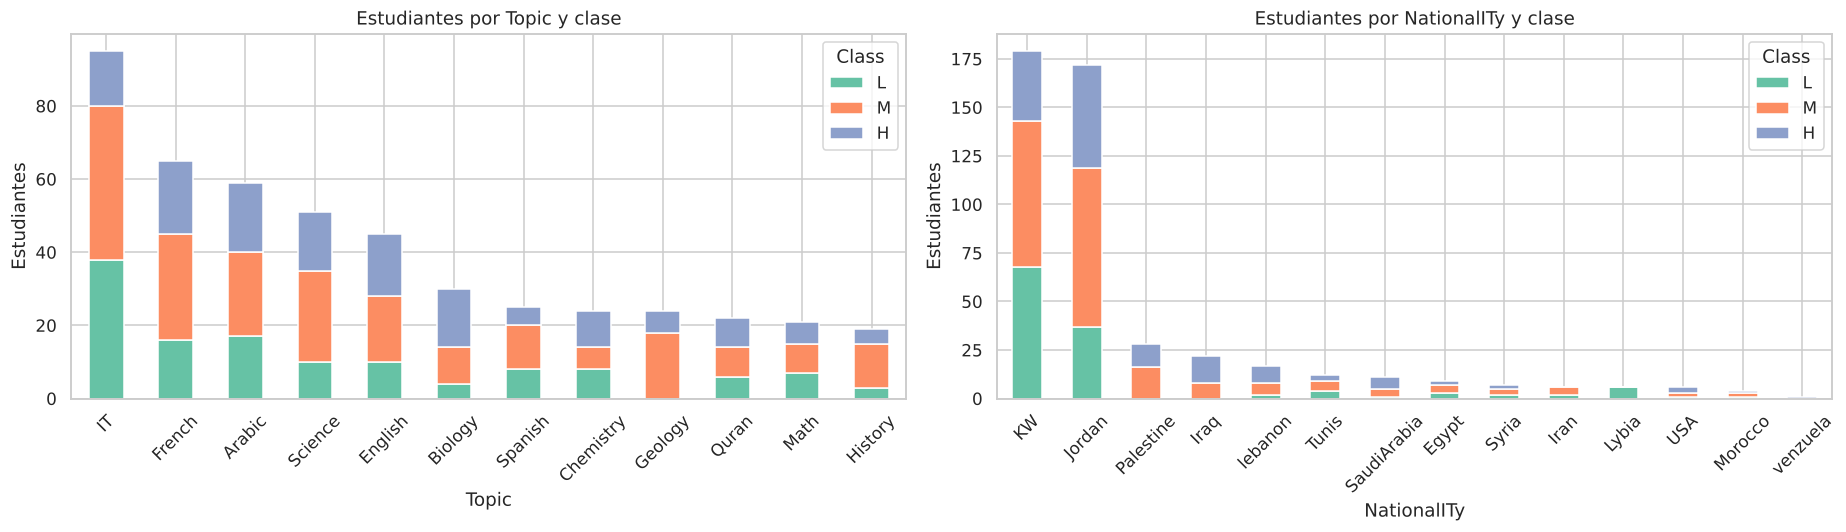

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
for a, c in zip(ax, ["Topic", "NationalITy"]):
    ct = pd.crosstab(df_raw[c], df_raw["Class"])[orden]
    ct = ct.loc[ct.sum(1).sort_values(ascending=False).index]
    ct.plot(kind="bar", stacked=True, ax=a, rot=45)
    a.set_title(f"Estudiantes por {c} y clase"); a.set_ylabel("Estudiantes")
plt.tight_layout(); plt.show()

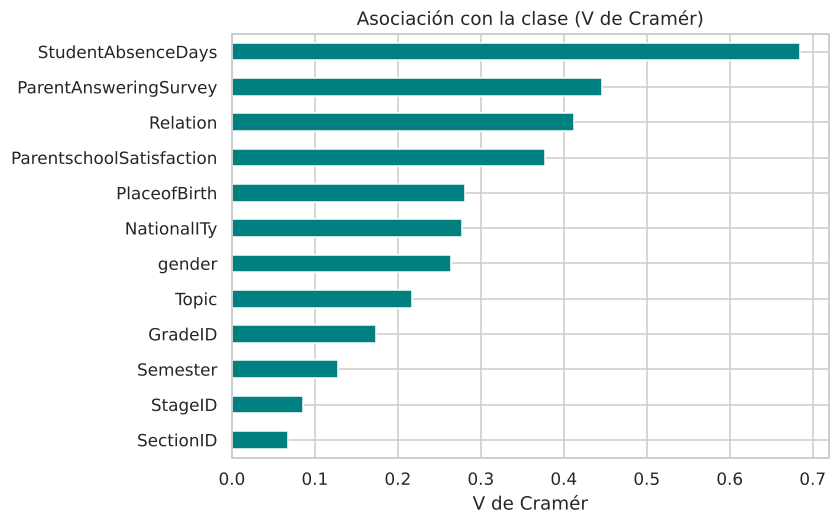

StudentAbsenceDays          0.685
ParentAnsweringSurvey       0.446
Relation                    0.412
ParentschoolSatisfaction    0.378
PlaceofBirth                0.280
NationalITy                 0.277
gender                      0.263
Topic                       0.217
GradeID                     0.174
Semester                    0.128
StageID                     0.086
SectionID                   0.068
dtype: float64

In [12]:
# Fuerza de asociación de cada variable categórica con la clase (V de Cramér)
from scipy.stats import chi2_contingency
def cramers_v(x, y):
    ct = pd.crosstab(x, y); chi2 = chi2_contingency(ct)[0]; n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
cat_cols = [c for c in df_raw.select_dtypes(exclude="number").columns if c != "Class"]
asoc = pd.Series({c: cramers_v(df_raw[c], df_raw["Class"]) for c in cat_cols}).sort_values()
asoc.plot(kind="barh", figsize=(7, 5), color="teal")
plt.title("Asociación con la clase (V de Cramér)"); plt.xlabel("V de Cramér"); plt.show()
asoc.sort_values(ascending=False).round(3)

### 1.6 Procesamiento según la modalidad (tabla) y conclusiones del EDA

Se trata de datos **tabulares** (480 registros, 17 columnas, 4 numéricas y 13 categóricas). Por eso no se tokeniza
texto ni se procesan imágenes: el procesamiento consiste en codificar las categorías y escalar las variables numéricas
para que la red neuronal las reciba en una escala comparable.

Hallazgos principales:

- **Calidad:** no hay valores nulos y solo hay 2 filas duplicadas exactas. Algunas categorías tienen errores de
  escritura (`KuwaIT`, `lebanon`, `venzuela`, `Tunis`, `Lybia`) que se normalizan en el paso 2.
- **Clase objetivo:** moderadamente desbalanceada (M ≈ 44 %, H ≈ 30 %, L ≈ 26 %). Se usará partición estratificada,
  **F1 macro** como métrica principal y aumento de datos para balancear el entrenamiento.
- **Interacción con la plataforma:** `VisITedResources` y `raisedhands` son las variables más correlacionadas
  con el rendimiento. Los estudiantes de nivel H visitan en promedio unos 79 recursos, frente a unos 18 en el nivel L.
  `Discussion` es la menos discriminante.
- **Ausencias:** `StudentAbsenceDays` es la variable categórica más asociada a la clase. Con más de 7 ausencias,
  la mayoría de los estudiantes queda en L.
- **Participación de los padres:** responder la encuesta (`ParentAnsweringSurvey`), la satisfacción con la escuela
  y que la responsable sea la madre (`Relation = Mum`) se asocian con mejor rendimiento.
- **Redundancia:** `PlaceofBirth` repite casi siempre la nacionalidad y `GradeID` se superpone con `StageID`; se
  conserva el grado como número y se descarta el país de nacimiento.
- Las clases se solapan (sobre todo M con H y M con L), así que un modelo no lineal como un MLP puede aportar frente a
  separadores lineales.

---
# PASO 2 · Preparación de datos y pipeline

1. Limpieza: nombres de columnas, normalización de países, eliminación de duplicados exactos.
2. Ingeniería de variables: `Grade` numérico (desde `GradeID`); nacionalidades con menos de 10 casos se agrupan en `Other`.
3. Codificación: binarias a 0/1, nominales con *One-Hot*; numéricas con `StandardScaler`.
4. Partición estratificada **70 % entrenamiento / 15 % validación / 15 % prueba**. El preprocesador se ajusta solo con
   entrenamiento para evitar fuga de información.
5. **Aumento de datos** (solo en entrenamiento): sobremuestreo con ruido gaussiano (*jittering*) sobre las variables
   numéricas para balancear las clases.

In [13]:
df = utils.limpiar(df_raw).drop_duplicates().reset_index(drop=True)
print("Registros tras eliminar duplicados:", len(df))
print("Nacionalidades finales:", df["Nationality"].value_counts().to_dict())

X = utils.preparar_X(df)
y = df["Class"].map({c: i for i, c in enumerate(utils.CLASES)}).values  # L=0, M=1, H=2
print("Columnas de entrada:", list(X.columns))
X.head()

Registros tras eliminar duplicados: 478
Nacionalidades finales: {'Kuwait': 179, 'Jordan': 170, 'Other': 39, 'Palestine': 28, 'Iraq': 22, 'Lebanon': 17, 'Tunisia': 12, 'SaudiArabia': 11}
Columnas de entrada: ['raisedhands', 'VisitedResources', 'AnnouncementsView', 'Discussion', 'Grade', 'gender', 'Semester', 'Relation', 'ParentAnsweringSurvey', 'ParentSchoolSatisfaction', 'StudentAbsenceDays', 'Nationality', 'StageID', 'SectionID', 'Topic']


,raisedhands,VisitedResources,AnnouncementsView,Discussion,Grade,gender,Semester,Relation,ParentAnsweringSurvey,ParentSchoolSatisfaction,StudentAbsenceDays,Nationality,StageID,SectionID,Topic
0,15,16,2,20,4,1.0,0.0,0.0,1.0,1.0,0.0,Kuwait,lowerlevel,A,IT
1,20,20,3,25,4,1.0,0.0,0.0,1.0,1.0,0.0,Kuwait,lowerlevel,A,IT
2,10,7,0,30,4,1.0,0.0,0.0,0.0,0.0,1.0,Kuwait,lowerlevel,A,IT
3,30,25,5,35,4,1.0,0.0,0.0,0.0,0.0,1.0,Kuwait,lowerlevel,A,IT
4,40,50,12,50,4,1.0,0.0,0.0,0.0,0.0,1.0,Kuwait,lowerlevel,A,IT


In [14]:
# Partición estratificada 70 / 15 / 15
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
part = pd.DataFrame({s: pd.Series(v).map(dict(enumerate(utils.CLASES))).value_counts()
                     for s, v in [("train", y_train), ("val", y_val), ("test", y_test)]}).loc[utils.CLASES]
part.loc["Total"] = part.sum()
part

,train,val,test
L,87,19,19
M,148,31,32
H,99,22,21
Total,334,72,72


In [15]:
# Pipeline de preprocesamiento (ajustado solo con entrenamiento)
preprocesador = ColumnTransformer([
    ("num", StandardScaler(), utils.NUMERICAS),
    ("bin", "passthrough", list(utils.BINARIAS)),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), utils.CATEGORICAS),
])
Xtr = preprocesador.fit_transform(X_train).astype(np.float32)
Xva = preprocesador.transform(X_val).astype(np.float32)
Xte = preprocesador.transform(X_test).astype(np.float32)
nombres_feat = list(preprocesador.get_feature_names_out())
print("Dimensión de entrada a la red:", Xtr.shape[1])
pd.DataFrame(Xtr, columns=nombres_feat).describe().T.head(12).round(2)

Dimensión de entrada a la red: 37


,count,mean,std,min,25%,50%,75%,max
num__raisedhands,334.0,-0.00,1.00,-1.51,-1.02,0.11,0.91,1.72
num__VisitedResources,334.0,0.00,1.00,-1.63,-1.06,0.32,0.88,1.33
num__AnnouncementsView,334.0,0.00,1.00,-1.45,-0.92,-0.06,0.75,2.23
num__Discussion,334.0,0.00,1.00,-1.56,-0.87,-0.15,0.93,1.98
num__Grade,334.0,-0.00,1.00,-1.24,-1.24,0.19,0.91,2.34
bin__gender,334.0,0.62,0.49,0.00,0.00,1.00,1.00,1.00
bin__Semester,334.0,0.48,0.50,0.00,0.00,0.00,1.00,1.00
bin__Relation,334.0,0.44,0.50,0.00,0.00,0.00,1.00,1.00
bin__ParentAnsweringSurvey,334.0,0.57,0.50,0.00,0.00,1.00,1.00,1.00
bin__ParentSchoolSatisfaction,334.0,0.61,0.49,0.00,0.00,1.00,1.00,1.00


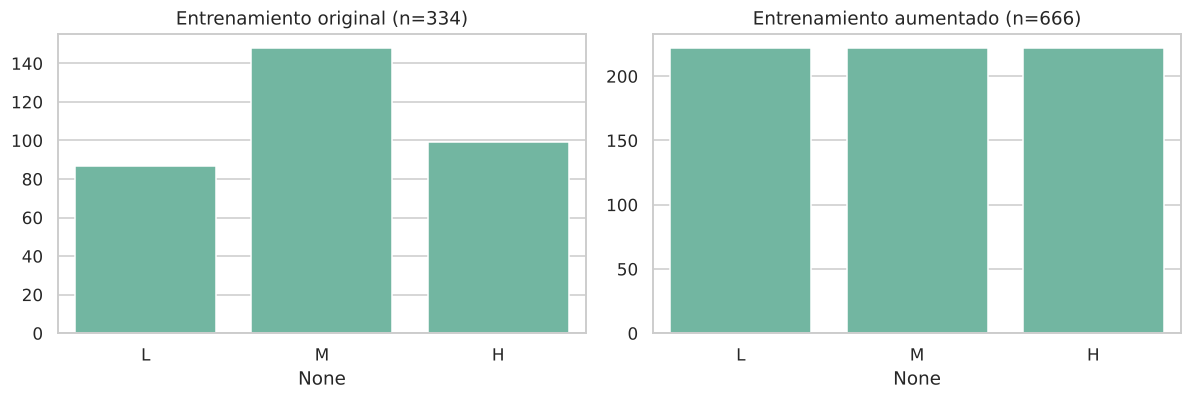

In [16]:
def aumentar_datos(X, y, idx_num, sigma=0.10, factor_extra=0.5, seed=SEED):
    """Aumento de datos tabulares por jittering.
    1) Sobremuestrea cada clase hasta igualar a la mayoritaria.
    2) Añade un `factor_extra` adicional de muestras sintéticas por clase.
    A las copias se les suma ruido gaussiano N(0, sigma) en las columnas numéricas escaladas;
    las columnas binarias y one-hot se copian tal cual para que sigan siendo válidas."""
    rng = np.random.default_rng(seed)
    n_obj = int(np.bincount(y).max() * (1 + factor_extra))
    Xs, ys = [X], [y]
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        n_new = n_obj - len(idx)
        sel = rng.choice(idx, size=n_new, replace=True)
        Xn = X[sel].copy()
        Xn[:, idx_num] += rng.normal(0, sigma, size=(n_new, len(idx_num))).astype(np.float32)
        Xs.append(Xn); ys.append(np.full(n_new, c))
    Xa, ya = np.vstack(Xs).astype(np.float32), np.concatenate(ys)
    p = rng.permutation(len(ya))
    return Xa[p], ya[p]

idx_num = list(range(len(utils.NUMERICAS)))
Xtr_aug, ytr_aug = aumentar_datos(Xtr, y_train, idx_num)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, yy, t in [(ax[0], y_train, f"Entrenamiento original (n={len(y_train)})"),
                 (ax[1], ytr_aug, f"Entrenamiento aumentado (n={len(ytr_aug)})")]:
    v = pd.Series(yy).map(dict(enumerate(utils.CLASES))).value_counts().reindex(utils.CLASES)
    sns.barplot(x=v.index, y=v.values, ax=a); a.set_title(t)
plt.tight_layout(); plt.show()

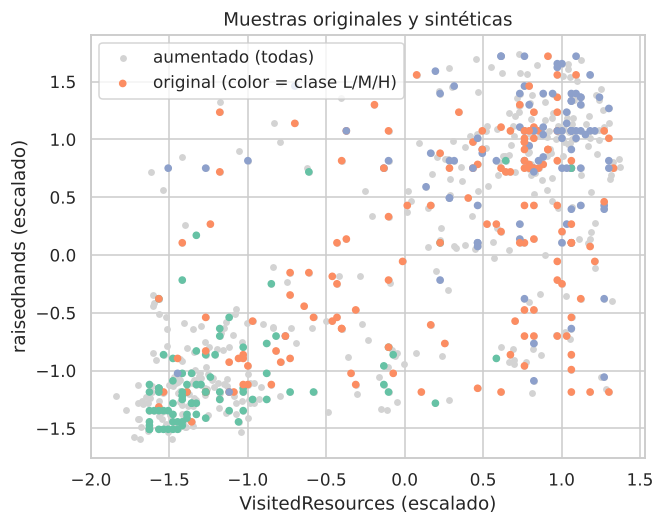

In [17]:
# Visualización del efecto del jittering: datos originales frente a sintéticos (2 variables escaladas)
plt.figure(figsize=(6.5, 5))
plt.scatter(Xtr_aug[:, 1], Xtr_aug[:, 0], c="lightgray", s=12, label="aumentado (todas)")
plt.scatter(Xtr[:, 1], Xtr[:, 0], c=[sns.color_palette("Set2")[k] for k in y_train], s=16, label="original (color = clase L/M/H)")
plt.xlabel("VisitedResources (escalado)"); plt.ylabel("raisedhands (escalado)")
plt.title("Muestras originales y sintéticas"); plt.legend(); plt.show()

In [18]:
# Tensores y DataLoaders de PyTorch
def loader(X, y, batch=32, shuffle=False):
    ds = TensorDataset(torch.tensor(X), torch.tensor(y, dtype=torch.long))
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, generator=g)

dl_train = loader(Xtr_aug, ytr_aug, shuffle=True)
dl_val = loader(Xva, y_val)
print(f"Lotes de entrenamiento: {len(dl_train)} | lotes de validación: {len(dl_val)}")

Lotes de entrenamiento: 21 | lotes de validación: 3


---
# PASO 3 · Modelado con Red Neuronal (MLP profundo)

**Justificación:** los datos son tabulares y no tienen estructura espacial (imágenes) ni secuencial (texto o series),
por lo que una CNN o una RNN no aportarían un sesgo inductivo útil. El catálogo del proyecto de Educación propone
**Perceptrones Multicapa (MLP) profundos**, adecuados para aprender combinaciones no lineales entre variables
de interacción, demográficas y familiares.

**Arquitectura** (`utils.MLPRendimiento`):

`Entrada (37) → [Linear → BatchNorm → ReLU → Dropout] × k → Linear 3 (logits)`

El número de capas ocultas, sus neuronas, el *dropout* y el *weight decay* se eligen por validación cruzada (sección 3.1).

- **BatchNorm** estabiliza y acelera el entrenamiento.
- **Dropout** y **weight decay (L2)** reducen el sobreajuste, un riesgo alto con solo ~330 registros de entrenamiento.
- Pérdida **CrossEntropy**, optimizador **AdamW**, *scheduler* `ReduceLROnPlateau` y **early stopping**
  sobre la pérdida de validación (se restauran los mejores pesos).

In [19]:
def evaluar(model, X, y, crit):
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(X))
        loss = crit(logits, torch.tensor(y, dtype=torch.long)).item()
        acc = (logits.argmax(1).numpy() == y).mean()
    return loss, acc

def entrenar(model, dl_tr, Xv, yv, epocas=400, lr=1e-3, wd=1e-3, paciencia=40, verbose=True):
    torch.manual_seed(SEED)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=15)
    hist = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
    mejor, mejor_estado, sin_mejora, mejor_ep = np.inf, None, 0, 0
    for ep in range(1, epocas + 1):
        model.train(); tot, ok, n = 0.0, 0, 0
        for xb, yb in dl_tr:
            if len(yb) < 2:  # BatchNorm necesita al menos 2 muestras por lote
                continue
            opt.zero_grad()
            out = model(xb); loss = crit(out, yb)
            loss.backward(); opt.step()
            tot += loss.item() * len(yb); ok += (out.argmax(1) == yb).sum().item(); n += len(yb)
        vl, va = evaluar(model, Xv, yv, crit)
        sched.step(vl)
        hist["loss"].append(tot / n); hist["acc"].append(ok / n)
        hist["val_loss"].append(vl); hist["val_acc"].append(float(va))
        if vl < mejor - 1e-4:
            mejor, sin_mejora, mejor_ep = vl, 0, ep
            mejor_estado = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            sin_mejora += 1
        if verbose and (ep % 25 == 0 or ep == 1):
            print(f"Época {ep:3d} | loss {tot/n:.4f} acc {ok/n:.3f} | val_loss {vl:.4f} val_acc {va:.3f}")
        if sin_mejora >= paciencia:
            if verbose: print(f"Early stopping en la época {ep}. Mejor época: {mejor_ep} (val_loss={mejor:.4f})")
            break
    model.load_state_dict(mejor_estado)
    return model, hist, mejor_ep

### 3.1 Búsqueda de hiperparámetros con validación cruzada
Con tan pocos datos, elegir la configuración usando un único conjunto de validación (72 registros) es inestable.
Por eso se usa **validación cruzada estratificada de 5 particiones** sobre entrenamiento + validación (el 85 % de los datos).
En cada partición el preprocesador y el aumento de datos se ajustan **solo** con los datos de entrenamiento de esa partición.
El conjunto de prueba no se usa en ningún momento de la búsqueda.

Se exploran: profundidad/anchura de la red, tasa de *dropout*, *weight decay* y uso o no de aumento de datos.

In [20]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
import itertools, time

X_dev = pd.concat([X_train, X_val]); y_dev = np.concatenate([y_train, y_val])
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_mlp(capas, dropout, wd, usar_aug):
    f1s = []
    for tr, va in skf.split(X_dev, y_dev):
        p = clone(preprocesador)
        Xa = p.fit_transform(X_dev.iloc[tr]).astype(np.float32); ya = y_dev[tr]
        Xb = p.transform(X_dev.iloc[va]).astype(np.float32); yb = y_dev[va]
        if usar_aug:
            Xa, ya = aumentar_datos(Xa, ya, idx_num)
        torch.manual_seed(SEED)
        m, _, _ = entrenar(utils.MLPRendimiento(Xa.shape[1], capas, dropout=dropout),
                           loader(Xa, ya, shuffle=True), Xb, yb, wd=wd, verbose=False)
        f1s.append(f1_score(yb, predecir_proba(m, Xb).argmax(1), average="macro"))
    return np.mean(f1s), np.std(f1s)

def predecir_proba(model, X):
    model.eval()
    with torch.no_grad():
        return torch.softmax(model(torch.tensor(X)), 1).numpy()

grid = list(itertools.product([(64, 32, 16), (32, 16), (16,)], [0.3, 0.5], [1e-3, 1e-2], [True, False]))
t0, filas = time.time(), []
for capas, do, wd, ag in grid:
    m_, s_ = cv_mlp(capas, do, wd, ag)
    filas.append({"capas": str(capas), "dropout": do, "weight_decay": wd, "aumento": ag, "F1_macro_CV": m_, "desv": s_})
busqueda = pd.DataFrame(filas).sort_values("F1_macro_CV", ascending=False).reset_index(drop=True)
print(f"{len(grid)} configuraciones x 5 particiones en {time.time()-t0:.0f} s")
busqueda.head(10).round(4)

24 configuraciones x 5 particiones en 293 s


,capas,dropout,weight_decay,aumento,F1_macro_CV,desv
0,"(64, 32, 16)",0.3,0.001,True,0.7742,0.0199
1,"(64, 32, 16)",0.5,0.010,False,0.7701,0.0409
2,"(64, 32, 16)",0.5,0.001,False,0.7667,0.0358
3,"(16,)",0.5,0.010,False,0.7646,0.0387
4,"(64, 32, 16)",0.3,0.010,True,0.7644,0.0210
5,"(32, 16)",0.3,0.010,True,0.7606,0.0503
6,"(16,)",0.5,0.001,False,0.7593,0.0344
7,"(64, 32, 16)",0.3,0.001,False,0.7579,0.0257
8,"(16,)",0.3,0.010,True,0.7576,0.0361
9,"(32, 16)",0.5,0.001,False,0.7528,0.0277


Mejor configuración: capas=(64, 32, 16), dropout=0.3, weight_decay=0.001, aumento=True
  F1 macro CV MLP              : 0.7742 ± 0.0199
  F1 macro CV mismo MLP sin aumento: 0.7579 ± 0.0257
  F1 macro CV Regresión logística: 0.7451 ± 0.0479


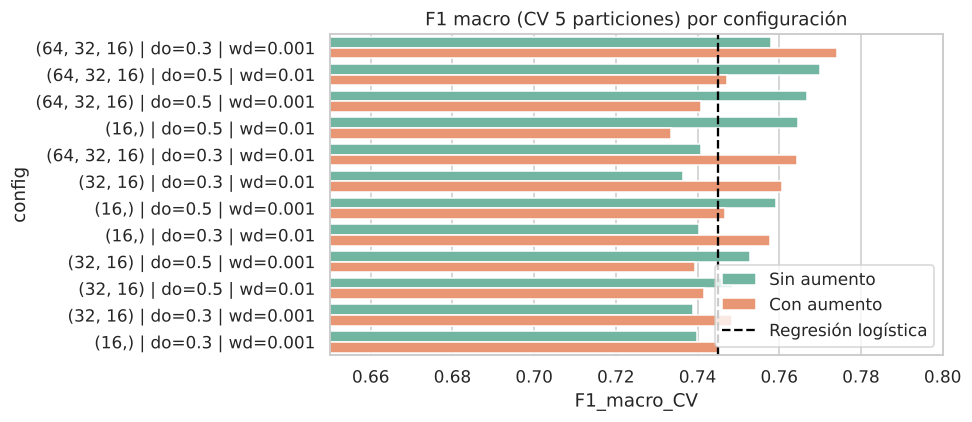

In [21]:
# Referencia lineal con la misma validación cruzada
f1_lr = []
for tr, va in skf.split(X_dev, y_dev):
    p = clone(preprocesador)
    lr_ = LogisticRegression(max_iter=2000).fit(p.fit_transform(X_dev.iloc[tr]), y_dev[tr])
    f1_lr.append(f1_score(y_dev[va], lr_.predict(p.transform(X_dev.iloc[va])), average="macro"))
cv_lr = (np.mean(f1_lr), np.std(f1_lr))

mejor = busqueda.iloc[0]
CAPAS, DROPOUT, WD, USAR_AUG = eval(mejor["capas"]), float(mejor["dropout"]), float(mejor["weight_decay"]), bool(mejor["aumento"])
mejor_sin_aug = busqueda[(busqueda.capas == mejor.capas) & (busqueda.dropout == mejor.dropout) &
                         (busqueda.weight_decay == mejor.weight_decay) & (~busqueda.aumento)].iloc[0]
print(f"Mejor configuración: capas={CAPAS}, dropout={DROPOUT}, weight_decay={WD}, aumento={USAR_AUG}")
print(f"  F1 macro CV MLP              : {mejor.F1_macro_CV:.4f} ± {mejor.desv:.4f}")
print(f"  F1 macro CV mismo MLP sin aumento: {mejor_sin_aug.F1_macro_CV:.4f} ± {mejor_sin_aug.desv:.4f}")
print(f"  F1 macro CV Regresión logística: {cv_lr[0]:.4f} ± {cv_lr[1]:.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
b = busqueda.copy(); b["config"] = b.capas + " | do=" + b.dropout.astype(str) + " | wd=" + b.weight_decay.astype(str)
sns.barplot(data=b, y="config", x="F1_macro_CV", hue="aumento", ax=ax, orient="h")
ax.axvline(cv_lr[0], ls="--", c="k", label="Regresión logística")
ax.set_xlim(0.65, 0.80); ax.set_title("F1 macro (CV 5 particiones) por configuración")
h, l = ax.get_legend_handles_labels()
ax.legend(h, [{"False": "Sin aumento", "True": "Con aumento"}.get(x, x) for x in l], loc="lower right")
plt.tight_layout(); plt.show()

### 3.2 Entrenamiento del modelo final
Con la mejor configuración se entrena el modelo final sobre el conjunto de entrenamiento (aumentado si la configuración lo
indica), usando el conjunto de validación para el *early stopping*.

In [22]:
dl_train = loader(Xtr_aug, ytr_aug, shuffle=True) if USAR_AUG else loader(Xtr, y_train, shuffle=True)
n_in = Xtr.shape[1]
torch.manual_seed(SEED)
modelo = utils.MLPRendimiento(n_in, CAPAS, dropout=DROPOUT)
print(modelo)
print("Parámetros entrenables:", sum(p.numel() for p in modelo.parameters() if p.requires_grad))
modelo, historial, mejor_epoca = entrenar(modelo, dl_train, Xva, y_val, wd=WD)

MLPRendimiento(
  (red): Sequential(
    (0): Linear(in_features=37, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=16, out_features=3, bias=True)
  )
)
Parámetros entrenables: 5315


Época   1 | loss 1.0949 acc 0.372 | val_loss 1.0958 val_acc 0.514


Época  25 | loss 0.4334 acc 0.841 | val_loss 0.8136 val_acc 0.694


Época  50 | loss 0.2698 acc 0.917 | val_loss 0.8812 val_acc 0.694


Early stopping en la época 69. Mejor época: 29 (val_loss=0.7710)


**Modelos de referencia.** Para valorar el aporte de la red y del aumento de datos se entrenan, con la misma partición:
(a) el mismo MLP (misma configuración) sin aumento de datos y (b) una regresión logística multinomial, un modelo lineal clásico.

In [23]:
torch.manual_seed(SEED)
modelo_sin_aug, hist_sin_aug, _ = entrenar(utils.MLPRendimiento(n_in, CAPAS, dropout=DROPOUT),
                                          loader(Xtr, y_train, shuffle=True), Xva, y_val, wd=WD, verbose=False)
logreg = LogisticRegression(max_iter=2000, C=1.0).fit(Xtr, y_train)
print("Modelos de referencia entrenados.")

Modelos de referencia entrenados.


---
# PASO 4 · Evaluación y métricas
### 4.1 Curvas de entrenamiento y validación

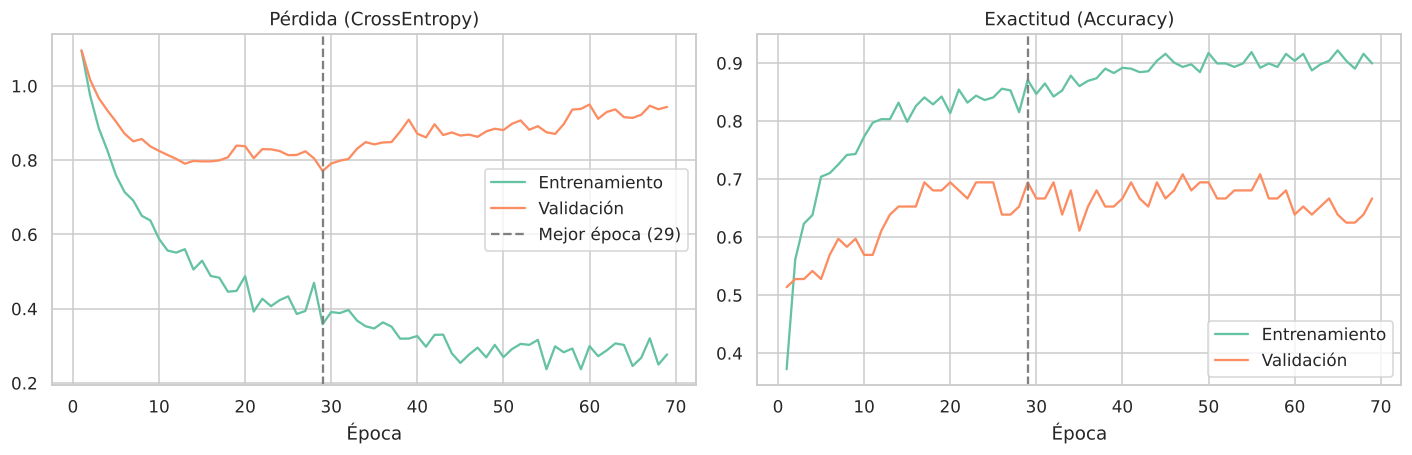

In [24]:
ep = range(1, len(historial["loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].plot(ep, historial["loss"], label="Entrenamiento"); ax[0].plot(ep, historial["val_loss"], label="Validación")
ax[0].axvline(mejor_epoca, ls="--", c="gray", label=f"Mejor época ({mejor_epoca})")
ax[0].set_title("Pérdida (CrossEntropy)"); ax[0].set_xlabel("Época"); ax[0].legend()
ax[1].plot(ep, historial["acc"], label="Entrenamiento"); ax[1].plot(ep, historial["val_acc"], label="Validación")
ax[1].axvline(mejor_epoca, ls="--", c="gray")
ax[1].set_title("Exactitud (Accuracy)"); ax[1].set_xlabel("Época"); ax[1].legend()
plt.tight_layout(); plt.show()

### 4.2 Métricas en el conjunto de prueba (datos nunca vistos)

In [25]:
def metricas(nombre, proba, y):
    pred = proba.argmax(1)
    return {"Modelo": nombre, "Accuracy": accuracy_score(y, pred),
            "F1 macro": f1_score(y, pred, average="macro"),
            "F1 ponderado": f1_score(y, pred, average="weighted"),
            "Log-loss": log_loss(y, proba, labels=[0, 1, 2])}

proba_test = predecir_proba(modelo, Xte)
y_pred = proba_test.argmax(1)
tabla = pd.DataFrame([
    metricas("MLP final", proba_test, y_test),
    metricas("MLP sin aumento", predecir_proba(modelo_sin_aug, Xte), y_test),
    metricas("Regresión logística (referencia)", logreg.predict_proba(Xte), y_test),
]).set_index("Modelo").round(4)
tabla["F1 macro CV (5 part.)"] = [mejor.F1_macro_CV, mejor_sin_aug.F1_macro_CV, cv_lr[0]]
tabla.round(4)

,Accuracy,F1 macro,F1 ponderado,Log-loss,F1 macro CV (5 part.)
Modelo,,,,,
MLP final,0.7639,0.7599,0.7538,0.6417,0.7742
MLP sin aumento,0.7222,0.7217,0.7142,0.6574,0.7579
Regresión logística (referencia),0.8056,0.8054,0.8011,0.6309,0.7451


In [26]:
print(classification_report(y_test, y_pred, target_names=[utils.NOMBRE_CLASE[c] for c in utils.CLASES], digits=3))

               precision    recall  f1-score   support

  Bajo (0-69)      0.826     1.000     0.905        19
Medio (70-89)      0.714     0.781     0.746        32
Alto (90-100)      0.786     0.524     0.629        21

     accuracy                          0.764        72
    macro avg      0.775     0.768     0.760        72
 weighted avg      0.765     0.764     0.754        72



### 4.3 Matriz de confusión

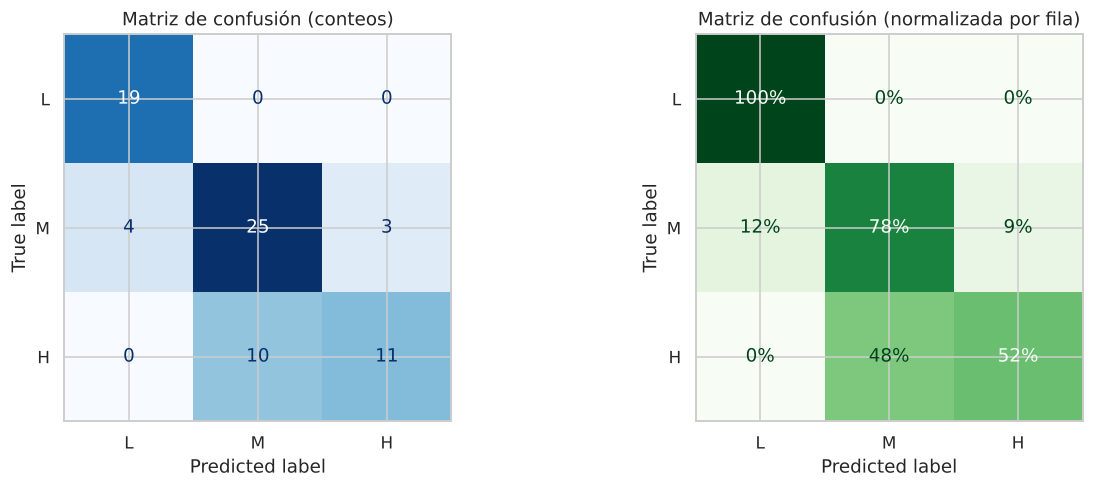

In [27]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ConfusionMatrixDisplay(cm, display_labels=utils.CLASES).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Matriz de confusión (conteos)")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, normalize="true"), display_labels=utils.CLASES).plot(
    ax=ax[1], cmap="Greens", colorbar=False, values_format=".0%")
ax[1].set_title("Matriz de confusión (normalizada por fila)")
plt.tight_layout(); plt.show()

### 4.4 Importancia de las variables (permutación sobre el conjunto de prueba)

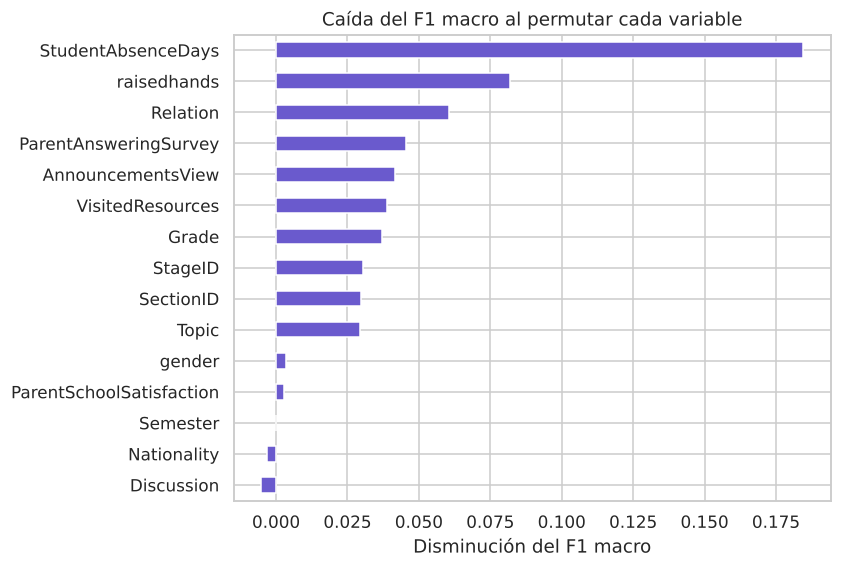

In [28]:
def importancia_permutacion(model, X_df, y, n_rep=30, seed=SEED):
    rng = np.random.default_rng(seed)
    base = f1_score(y, predecir_proba(model, preprocesador.transform(X_df).astype(np.float32)).argmax(1), average="macro")
    res = {}
    for col in X_df.columns:
        caidas = []
        for _ in range(n_rep):
            Xp = X_df.copy(); Xp[col] = rng.permutation(Xp[col].values)
            p = predecir_proba(model, preprocesador.transform(Xp).astype(np.float32)).argmax(1)
            caidas.append(base - f1_score(y, p, average="macro"))
        res[col] = np.mean(caidas)
    return pd.Series(res).sort_values()

imp = importancia_permutacion(modelo, X_test, y_test)
imp.plot(kind="barh", figsize=(7, 5.5), color="slateblue")
plt.title("Caída del F1 macro al permutar cada variable"); plt.xlabel("Disminución del F1 macro"); plt.show()

### 4.5 Guardado del modelo y del pipeline para Streamlit

In [29]:
Path("modelo").mkdir(exist_ok=True)
torch.save(modelo.state_dict(), "modelo/mlp_rendimiento.pt")
joblib.dump(preprocesador, "modelo/preprocesador.joblib")

metadata = {
    "n_entradas": int(n_in), "capas": list(CAPAS), "dropout": DROPOUT, "weight_decay": WD, "aumento": USAR_AUG, "clases": utils.CLASES,
    "origen_datos": ORIGEN, "mejor_epoca": int(mejor_epoca),
    "metricas_test": tabla.round(4).reset_index().to_dict(orient="records"),
    "busqueda_cv": busqueda.round(4).to_dict(orient="records"),
    "reporte": classification_report(y_test, y_pred, target_names=utils.CLASES, output_dict=True),
    "matriz_confusion": cm.tolist(),
    "historial": historial,
    "importancia": imp.sort_values(ascending=False).round(4).to_dict(),
    "particion": {"train": int(len(y_train)), "train_aumentado": int(len(ytr_aug)),
                  "val": int(len(y_val)), "test": int(len(y_test))},
    "categorias": {c: sorted(X[c].unique().tolist()) for c in utils.CATEGORICAS},
}
with open("modelo/metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)
print("Archivos guardados en ./modelo:", [p.name for p in Path("modelo").iterdir()])

Archivos guardados en ./modelo: ['mlp_rendimiento.pt', 'metadata.json', 'preprocesador.joblib']


In [30]:
# Prueba de recarga: el modelo guardado produce las mismas predicciones
m2 = utils.MLPRendimiento(n_in, CAPAS, dropout=DROPOUT); m2.load_state_dict(torch.load("modelo/mlp_rendimiento.pt")); m2.eval()
pp = joblib.load("modelo/preprocesador.joblib")
assert (predecir_proba(m2, pp.transform(X_test).astype(np.float32)).argmax(1) == y_pred).all()
print("Recarga verificada ✔")

Recarga verificada ✔


### 4.6 Interpretación de resultados y conclusiones

**Desempeño.** En el conjunto de prueba (72 estudiantes nunca vistos) el MLP final obtiene **Accuracy = 0,764** y
**F1 macro = 0,760**. En validación cruzada de 5 particiones (más estable) alcanza **F1 macro = 0,774 ± 0,020**,
el mejor resultado de todas las configuraciones evaluadas.

**Aporte del aumento de datos.** Con la misma arquitectura, el aumento por *jittering* mejora el F1 macro tanto en
validación cruzada (0,774 frente a 0,758) como en prueba (0,760 frente a 0,722) y reduce la variabilidad entre particiones.

**Comparación con un modelo lineal.** En validación cruzada el MLP supera a la regresión logística (0,774 frente a 0,745).
En la partición de prueba ocurre lo contrario (0,805 para la regresión logística). Con solo 72 registros de prueba,
una diferencia de 3 aciertos mueve el F1 unos 4 puntos, así que se toma como referencia principal el promedio de
validación cruzada. La conclusión honesta es que, con 480 registros tabulares, la red neuronal y un modelo lineal bien
regularizado rinden de forma parecida; la red ofrece una ganancia moderada y probabilidades bien calibradas
(log-loss ≈ 0,64).

**Matriz de confusión.** La red identifica a **todos** los estudiantes de rendimiento bajo (recall L = 100 %), lo
más valioso para una alerta temprana. El principal error es confundir **H con M** (10 de 21 estudiantes H se predicen
como M). Los errores casi siempre ocurren entre clases vecinas; nunca se confunde L con H.

**Curvas de aprendizaje.** La pérdida de validación alcanza su mínimo hacia la época 29 y luego sube mientras la de
entrenamiento sigue bajando, señal de sobreajuste. El *early stopping* restaura los pesos de la mejor época, y el
*dropout* y el *weight decay* lo contienen.

**Variables más influyentes.** `StudentAbsenceDays` es, con diferencia, la más importante, seguida de `raisedhands`,
`Relation` (madre como responsable), `ParentAnsweringSurvey`, `AnnouncementsView` y `VisitedResources`. Esto coincide
con el EDA: asistencia, participación activa e involucramiento de los padres son las señales clave.

**Limitaciones.** El dataset es pequeño y muchos estudiantes aparecen dos veces (semestres F y S) con valores casi
idénticos. Como no hay identificador de estudiante, la partición no puede agruparlos y las métricas podrían ser algo
optimistas. Recolectar más datos o un identificador permitiría una validación más estricta.

---
# PASO 5 · Despliegue en Streamlit

La aplicación `app.py` carga `modelo/mlp_rendimiento.pt`, `modelo/preprocesador.joblib` y `modelo/metadata.json`
y ofrece cuatro secciones:

1. **Predicción individual:** formulario con los datos de un estudiante → nivel predicho y probabilidades por clase.
2. **Predicción por lotes:** carga de un CSV con el formato de xAPI-Edu-Data y descarga de las predicciones.
3. **Exploración de datos:** gráficos interactivos del dataset, leído desde Google Drive (con respaldo local).
4. **Desempeño del modelo:** métricas, curvas de entrenamiento, matriz de confusión e importancia de variables.

**Ejecución local:**
```bash
pip install -r requirements.txt
streamlit run app.py
```
**Despliegue en Streamlit Community Cloud:** subir la carpeta del proyecto a un repositorio de GitHub
(incluyendo `modelo/`, `data/`, `utils.py`, `app.py` y `requirements.txt`) y crear la app en
https://share.streamlit.io apuntando a `app.py`.